In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data Preparation

In [2]:
from sklearn.datasets import load_breast_cancer

frame = load_breast_cancer(as_frame=True)
df = frame['data']
X = df.values
y = np.array(frame['target'])

df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


# Data Partitioning

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100, stratify=y)

# Normalization

In [5]:
from sklearn.preprocessing import StandardScaler

In [6]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# Single Perceptron

In [7]:
from sklearn.linear_model import Perceptron

In [ ]:
from sklearn.datasets import load_digits
from sklearn.linear_model import Perceptron
X, y = load_digits(return_X_y=True)
clf = Perceptron(tol=1e-3, random_state=0)
clf.fit(X, y)
clf.score(X, y)

# Sklearn Multilayer Perceptron

In [7]:
from sklearn.neural_network import MLPClassifier

In [8]:
hidden_layer_sizes = (100, 200,)

### Parameters
https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

hidden_layer_sizes tuple, length = n_layers - 2, default=(100,)
The ith element represents the number of neurons in the ith hidden layer.

activation {'identity', 'logistic', 'tanh', 'relu'}, default='relu'
Activation function for the hidden layer.
* 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x
* 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).
* 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).
* 'relu', the rectified linear unit function, returns f(x) = max(0, x)

solver {'lbfgs', 'sgd', 'adam'}, default='adam'
The solver for weight optimization.
* 'lbfgs' is an optimizer in the family of quasi-Newton methods.
* 'sgd' refers to stochastic gradient descent.
* 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy Ba
The default solver 'adam' works pretty well on relatively large datasets (>= 1000 training samples) in terms of both training time and validation score. For small datasets, 'lbfgs' can converge faster and perform better.

alpha float, default=0.0001
L2 penalty (regularization term) parameter.

batch_size int, default='auto'
Size of minibatches for stochastic optimizers. If the solver is 'lbfgs', the classifier will not use minibatch. When set to “auto”, batch_size=min(200, n_samples)

learning_rate {'constant', 'invscaling', 'adaptive'}, default='constant'
Learning rate schedule for weight updates.
*'constant' is a constant learning rate given by 'learning_rate_init'.
*'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of *'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)
*'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.
Only used when solver='sgd'.

learning_rate_init double, default=0.001
The initial learning rate used. It controls the step-size in updating the weights. Only used when solver='sgd' or 'adam'.

power_t double, default=0.5
The exponent for inverse scaling learning rate. It is used in updating effective learning rate when the learning_rate is set to 'invscaling'. Only used when solver='sgd'.

max_iter int, default=200
Maximum number of iterations. The solver iterates until convergence (determined by 'tol') or this number of iterations. For stochastic solvers ('sgd', 'adam'), note that this determines the number of epochs (how many times each data point will be used), not the number of gradient steps.

shuffle bool, default=True
Whether to shuffle samples in each iteration. Only used when solver='sgd' or 'adam'.

random_state int, RandomState instance or None, default=None
If int, random_state is the seed used by the random number generator; If RandomState instance, random_state is the random number generator; If None, the random number generator is the RandomState instance used by np.random.

tol float, default=1e-4
Tolerance for the optimization. When the loss or score is not improving by at least tol for n_iter_no_change consecutive iterations, unless learning_rate is set to 'adaptive', convergence is considered to be reached and training stops.

verbose bool, default=False
Whether to print progress messages to stdout.

warm_start bool, default=False
When set to True, reuse the solution of the previous call to fit as initialization, otherwise, just erase the previous solution. See the Glossary.

momentum float, default=0.9
Momentum for gradient descent update. Should be between 0 and 1. Only used when solver='sgd'.

early_stopping bool, default=False
Whether to use early stopping to terminate training when validation score is not improving. If set to true, it will automatically set aside 10% of training data as validation and terminate training when validation score is not improving by at least tol for n_iter_no_change consecutive epochs. The split is stratified, except in a multilabel setting. Only effective when solver='sgd' or 'adam'

validation_fraction float, default=0.1
The proportion of training data to set aside as validation set for early stopping. Must be between 0 and 1. Only used if early_stopping is True

beta_1 float, default=0.9
Exponential decay rate for estimates of first moment vector in adam, should be in [0, 1). Only used when solver='adam'

beta_2 float, default=0.999
Exponential decay rate for estimates of second moment vector in adam, should be in [0, 1). Only used when solver='adam'

epsilon float, default=1e-8
Value for numerical stability in adam. Only used when solver='adam'

n_iter_no_change int, default=10
Maximum number of epochs to not meet tol improvement. Only effective when solver='sgd' or 'adam'


### Attributes
loss_ float
The current loss computed with the loss function.

coefs_ list, length n_layers - 1
The ith element in the list represents the weight matrix corresponding to layer i.

intercepts_ list, length n_layers - 1
The ith element in the list represents the bias vector corresponding to layer i + 1.

n_iter_ int,
The number of iterations the solver has ran.

n_layers_ int
Number of layers.

n_outputs_ int
Number of outputs.

out_activation_ string
Name of the output activation function.

In [9]:
clf = MLPClassifier(random_state=0)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print('Accuracy %s' % accuracy_score(y_test, y_pred))
print('F1-score %s' % f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))

Accuracy 0.9883040935672515
F1-score [0.984375   0.99065421]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



/opt/homebrew/Caskroom/miniforge/base/envs/dm2_pytorch/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


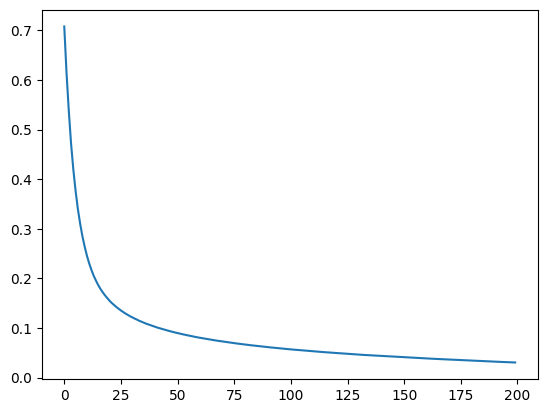

In [10]:
plt.plot(clf.loss_curve_)
plt.show()

In [11]:
clf = MLPClassifier(hidden_layer_sizes=(128, 64, 32,), alpha=0.1,
                    learning_rate='adaptive',
                    activation='tanh', early_stopping=False,
                    momentum=0.9, random_state=0, max_iter=500)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print('Accuracy %s' % accuracy_score(y_test, y_pred))
print('F1-score %s' % f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))

Accuracy 0.9707602339181286
F1-score [0.96062992 0.97674419]
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        64
           1       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



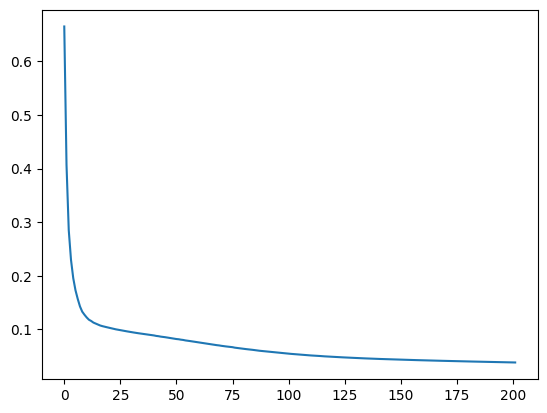

In [12]:
plt.plot(clf.loss_curve_)
plt.show()

In [13]:
clf = MLPClassifier(hidden_layer_sizes=(128, 64, 32,), alpha=0.1, learning_rate='adaptive',
                    activation='tanh', early_stopping=True, momentum=0.9, random_state=0)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print('Accuracy %s' % accuracy_score(y_test, y_pred))
print('F1-score %s' % f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))

Accuracy 0.9707602339181286
F1-score [0.96062992 0.97674419]
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        64
           1       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



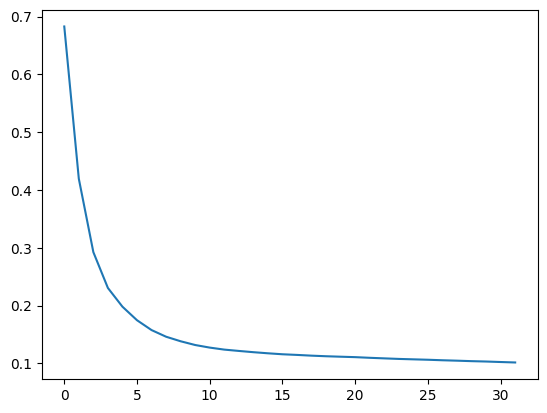

In [14]:
plt.plot(clf.loss_curve_)
plt.show()

In [15]:
from sklearn.model_selection import RandomizedSearchCV

In [16]:
param_list = {
    'hidden_layer_sizes': [(256, 128, 64,), (128, 64, 32,), (64, 32,)],
    'alpha': [0.1, 0.01, 0.001],
    'activation': ['tanh', 'relu', 'logistic'],
    'solver': ['sgd', 'adam'],
    'early_stopping': [True, False]
}

In [17]:
random_search = RandomizedSearchCV(
    MLPClassifier(random_state=0, max_iter=1000),
    param_distributions=param_list,
    n_jobs=-1,
    refit=True,
    verbose=2
)

In [18]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(estimator=MLPClassifier(max_iter=1000, random_state=0),
                   n_jobs=-1,
                   param_distributions={'activation': ['tanh', 'relu',
                                                       'logistic'],
                                        'alpha': [0.1, 0.01, 0.001],
                                        'early_stopping': [True, False],
                                        'hidden_layer_sizes': [(256, 128, 64),
                                                               (128, 64, 32),
                                                               (64, 32)],
                                        'solver': ['sgd', 'adam']},
                   verbose=2)

In [19]:
print(random_search.best_params_, random_search.best_score_)

{'solver': 'sgd', 'hidden_layer_sizes': (128, 64, 32), 'early_stopping': False, 'alpha': 0.001, 'activation': 'tanh'} 0.9749050632911394


# PyTorch
https://pytorch-ignite.ai/

PyTorch Ignite is a high-level library built on top of PyTorch that provides a set of abstractions and utilities for training and evaluating neural networks. It aims to simplify the process of developing and running complex training loops while providing flexibility and scalability. 

In [20]:
# !pip3 install torch
# !pip install torchsummary
# !pip install pytorch-ignite

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchsummary import summary
from torch.utils.data import TensorDataset, DataLoader

from ignite.metrics import Accuracy, Loss
from ignite.engine import Engine, Events, create_supervised_trainer, create_supervised_evaluator

In [22]:
# creates validation set
X_val, X_new_test, y_val, y_new_test = train_test_split(X_test, y_test, test_size=0.2, random_state=42, stratify=y_test)

In [23]:
# numpy to tensor
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

In [24]:
# creates tensor dataset (can be later loaded)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [25]:
# creates data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [27]:
class CustomModel(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, output_size):
        super(CustomModel, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, output_size)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

In [28]:
# define hyperparameters
n_classes = len(np.unique(y_train))
input_size = X_train.shape[1]
hidden_size1 = 128
hidden_size2 = 64
output_size = n_classes

In [29]:
# instanciates model
model = CustomModel(input_size, hidden_size1, hidden_size2, output_size)

In [30]:
summary(model, input_size=(input_size,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 128]           3,968
              ReLU-2                  [-1, 128]               0
            Linear-3                   [-1, 64]           8,256
              ReLU-4                   [-1, 64]               0
            Linear-5                    [-1, 2]             130
           Softmax-6                    [-1, 2]               0
Total params: 12,354
Trainable params: 12,354
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.05
Estimated Total Size (MB): 0.05
----------------------------------------------------------------


In [31]:
# optimizer and loss function
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

Define the ignite engine trainer, and two evaluator engines by passing Ignite’s out-of-the-box metrics and the model to create_supervised_evaluator. <br> These are abstraction for the train and eval loops.

In [32]:
# ignite trainer
trainer = create_supervised_trainer(model, optimizer, criterion, device)

# validation metrics are ignite metrics
val_metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)}

# ignite train and validation evaluators
train_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)
val_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)

training_history = {'accuracy':[],'loss':[]}
validation_history = {'accuracy':[],'loss':[]}

Engine allows adding handlers on various events that are triggered during the run. When an event is triggered, attached handlers (functions) are executed.

In [33]:
# For logging purposes we add a function to be executed at the end of every log_interval-th iteration:
log_interval = 100

@trainer.on(Events.ITERATION_COMPLETED(every=log_interval))
def log_training_loss(engine):
    print(f"Epoch[{engine.state.epoch}], Iter[{engine.state.iteration}] Loss: {engine.state.output:.2f}")

# after a training epoch, computes training and validation metrics (train_eval on train_loader and val_eval on val_loader)
@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(trainer):
    train_evaluator.run(train_loader)
    metrics = train_evaluator.state.metrics
    training_history['accuracy'].append(metrics['accuracy']*100)
    training_history['loss'].append(metrics['loss'])
    print(f"Training Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

@trainer.on(Events.EPOCH_COMPLETED)
def log_validation_results(trainer):
    val_evaluator.run(val_loader)
    metrics = val_evaluator.state.metrics
    validation_history['accuracy'].append(metrics['accuracy']*100)
    validation_history['loss'].append(metrics['loss'])
    print(f"Validation Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

In [34]:
trainer.run(train_loader, max_epochs=300)

Training Results - Epoch[1] Avg accuracy: 0.94 Avg loss: 0.53
Validation Results - Epoch[1] Avg accuracy: 0.95 Avg loss: 0.52
Training Results - Epoch[2] Avg accuracy: 0.94 Avg loss: 0.41
Validation Results - Epoch[2] Avg accuracy: 0.97 Avg loss: 0.40
Training Results - Epoch[3] Avg accuracy: 0.96 Avg loss: 0.37
Validation Results - Epoch[3] Avg accuracy: 0.97 Avg loss: 0.36
Training Results - Epoch[4] Avg accuracy: 0.98 Avg loss: 0.35
Validation Results - Epoch[4] Avg accuracy: 0.99 Avg loss: 0.34
Training Results - Epoch[5] Avg accuracy: 0.98 Avg loss: 0.34
Validation Results - Epoch[5] Avg accuracy: 0.98 Avg loss: 0.34
Training Results - Epoch[6] Avg accuracy: 0.98 Avg loss: 0.34
Validation Results - Epoch[6] Avg accuracy: 0.98 Avg loss: 0.34
Training Results - Epoch[7] Avg accuracy: 0.98 Avg loss: 0.33
Validation Results - Epoch[7] Avg accuracy: 0.98 Avg loss: 0.34
Epoch[8], Iter[100] Loss: 0.32
Training Results - Epoch[8] Avg accuracy: 0.99 Avg loss: 0.33
Validation Results - Epoc

State:
	iteration: 3900
	epoch: 300
	epoch_length: 13
	max_epochs: 300
	output: 0.3132636249065399
	batch: <class 'list'>
	metrics: <class 'dict'>
	dataloader: <class 'torch.utils.data.dataloader.DataLoader'>
	seed: <class 'NoneType'>
	times: <class 'dict'>

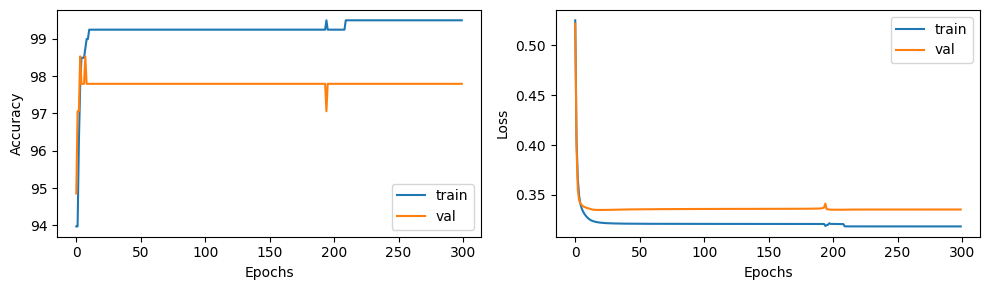

In [35]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
axes[0].plot(training_history['accuracy'], label='train')
axes[0].plot(validation_history['accuracy'], label='val')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(training_history['loss'], label='train')
axes[1].plot(validation_history['loss'], label='val')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
fig.tight_layout()

plt.show()

### Early Stopping

In [36]:
from ignite.handlers import EarlyStopping, ModelCheckpoint
from ignite.contrib.handlers import global_step_from_engine

In [37]:
# model + optimizer + criterion
model = CustomModel(input_size, hidden_size1, hidden_size2, output_size)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# ignite trainer + evaluators
trainer = create_supervised_trainer(model, optimizer, criterion, device)
val_metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)}
train_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)
val_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)

training_history = {'accuracy':[],'loss':[]}
validation_history = {'accuracy':[],'loss':[]}

# loggers + history appends
@trainer.on(Events.ITERATION_COMPLETED(every=log_interval))
def log_training_loss(engine):
    print(f"Epoch[{engine.state.epoch}], Iter[{engine.state.iteration}] Loss: {engine.state.output:.2f}")

# after a training epoch, computes training and validation metrics (train_eval on train_loader and val_eval on val_loader)
@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(trainer):
    train_evaluator.run(train_loader)
    metrics = train_evaluator.state.metrics
    training_history['accuracy'].append(metrics['accuracy']*100)
    training_history['loss'].append(metrics['loss'])
    print(f"Training Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

@trainer.on(Events.EPOCH_COMPLETED)
def log_validation_results(trainer):
    val_evaluator.run(val_loader)
    metrics = val_evaluator.state.metrics
    validation_history['accuracy'].append(metrics['accuracy']*100)
    validation_history['loss'].append(metrics['loss'])
    print(f"Validation Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

In [38]:
# return current value of any metric defined in val_metrics
def score_function(engine):
    return engine.state.metrics["accuracy"]

In [39]:
# define early stopping and model checkpoint
handler = EarlyStopping(patience=50, score_function=score_function, trainer=trainer)

checkpoint = ModelCheckpoint(
    dirname='models',
    filename_prefix='best_NOREG',
    n_saved=1,
    create_dir=True,
    global_step_transform=global_step_from_engine(trainer) # helps fetch the trainer's state
)

# Attach early stopping and model checkpoint to the trainer
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, handler)
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, checkpoint, {'model': model})

In [40]:
trainer.run(train_loader, max_epochs=300)

Training Results - Epoch[1] Avg accuracy: 0.94 Avg loss: 0.52
Validation Results - Epoch[1] Avg accuracy: 0.96 Avg loss: 0.52
Training Results - Epoch[2] Avg accuracy: 0.94 Avg loss: 0.40
Validation Results - Epoch[2] Avg accuracy: 0.97 Avg loss: 0.39
Training Results - Epoch[3] Avg accuracy: 0.96 Avg loss: 0.36
Validation Results - Epoch[3] Avg accuracy: 0.99 Avg loss: 0.35
Training Results - Epoch[4] Avg accuracy: 0.97 Avg loss: 0.35
Validation Results - Epoch[4] Avg accuracy: 0.99 Avg loss: 0.34
Training Results - Epoch[5] Avg accuracy: 0.98 Avg loss: 0.34
Validation Results - Epoch[5] Avg accuracy: 0.98 Avg loss: 0.34
Training Results - Epoch[6] Avg accuracy: 0.98 Avg loss: 0.34
Validation Results - Epoch[6] Avg accuracy: 0.98 Avg loss: 0.34
Training Results - Epoch[7] Avg accuracy: 0.98 Avg loss: 0.33
Validation Results - Epoch[7] Avg accuracy: 0.99 Avg loss: 0.33
Epoch[8], Iter[100] Loss: 0.32
Training Results - Epoch[8] Avg accuracy: 0.98 Avg loss: 0.33
Validation Results - Epoc

2024-05-07 10:54:52,688 ignite.handlers.early_stopping.EarlyStopping INFO: EarlyStopping: Stop training


Training Results - Epoch[36] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[36] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[37] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[37] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[38] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[38] Avg accuracy: 0.97 Avg loss: 0.34
Epoch[39], Iter[500] Loss: 0.31
Training Results - Epoch[39] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[39] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[40] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[40] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[41] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[41] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[42] Avg accuracy: 0.99 Avg loss: 0.32
Validation Results - Epoch[42] Avg accuracy: 0.97 Avg loss: 0.34
Training Results - Epoch[43] Avg accuracy: 0.99 Avg loss: 0.32
Validatio

State:
	iteration: 689
	epoch: 53
	epoch_length: 13
	max_epochs: 300
	output: 0.3134715259075165
	batch: <class 'list'>
	metrics: <class 'dict'>
	dataloader: <class 'torch.utils.data.dataloader.DataLoader'>
	seed: <class 'NoneType'>
	times: <class 'dict'>

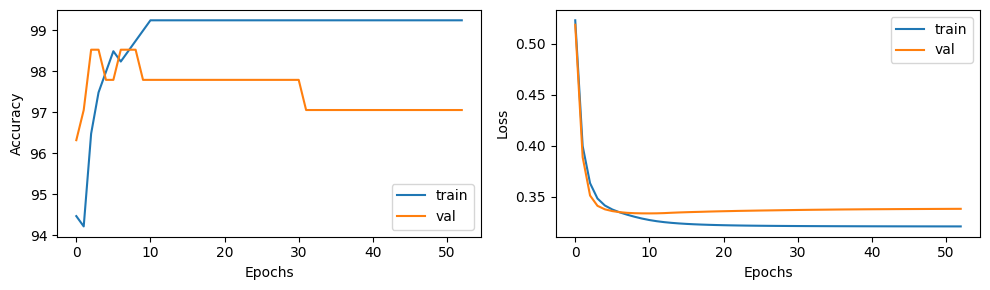

In [41]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
axes[0].plot(training_history['accuracy'], label='train')
axes[0].plot(validation_history['accuracy'], label='val')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(training_history['loss'], label='train')
axes[1].plot(validation_history['loss'], label='val')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
fig.tight_layout()

plt.show()

### L2 Regularization
https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam <br>
weight_decay (float, optional) – weight decay (L2 penalty) (default: 0)

In [42]:
class L2Model(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(L2Model, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, hidden_dim)
        self.fc5 = nn.Linear(hidden_dim, output_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.fc5(x)
        return x

In [43]:
hidden_dim = 100

In [44]:
# model + optimizer + criterion
model = L2Model(input_size, hidden_dim, n_classes)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)
criterion = nn.CrossEntropyLoss()

# ignite trainer + evaluators
trainer = create_supervised_trainer(model, optimizer, criterion, device)
val_metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)}
train_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)
val_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)

training_history = {'accuracy':[],'loss':[]}
validation_history = {'accuracy':[],'loss':[]}

# loggers + history appends
@trainer.on(Events.ITERATION_COMPLETED(every=log_interval))
def log_training_loss(engine):
    print(f"Epoch[{engine.state.epoch}], Iter[{engine.state.iteration}] Loss: {engine.state.output:.2f}")

# after a training epoch, computes training and validation metrics (train_eval on train_loader and val_eval on val_loader)
@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(trainer):
    train_evaluator.run(train_loader)
    metrics = train_evaluator.state.metrics
    training_history['accuracy'].append(metrics['accuracy']*100)
    training_history['loss'].append(metrics['loss'])
    print(f"Training Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

@trainer.on(Events.EPOCH_COMPLETED)
def log_validation_results(trainer):
    val_evaluator.run(val_loader)
    metrics = val_evaluator.state.metrics
    validation_history['accuracy'].append(metrics['accuracy']*100)
    validation_history['loss'].append(metrics['loss'])
    print(f"Validation Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

In [45]:
# Define early stopping and model checkpoint
handler = EarlyStopping(patience=50, score_function=score_function, trainer=trainer)
checkpoint = ModelCheckpoint('models', filename_prefix='best_L2', n_saved=1, global_step_transform=global_step_from_engine(trainer), require_empty=False)

# Attach early stopping and model checkpoint to the trainer
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, handler)
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, checkpoint, {'model': model})

In [46]:
trainer.run(train_loader, max_epochs=300)

Training Results - Epoch[1] Avg accuracy: 0.91 Avg loss: 0.46
Validation Results - Epoch[1] Avg accuracy: 0.93 Avg loss: 0.45
Training Results - Epoch[2] Avg accuracy: 0.94 Avg loss: 0.13
Validation Results - Epoch[2] Avg accuracy: 0.99 Avg loss: 0.10
Training Results - Epoch[3] Avg accuracy: 0.98 Avg loss: 0.07
Validation Results - Epoch[3] Avg accuracy: 0.99 Avg loss: 0.06
Training Results - Epoch[4] Avg accuracy: 0.98 Avg loss: 0.06
Validation Results - Epoch[4] Avg accuracy: 0.99 Avg loss: 0.05
Training Results - Epoch[5] Avg accuracy: 0.99 Avg loss: 0.05
Validation Results - Epoch[5] Avg accuracy: 0.99 Avg loss: 0.05
Training Results - Epoch[6] Avg accuracy: 0.99 Avg loss: 0.04
Validation Results - Epoch[6] Avg accuracy: 0.99 Avg loss: 0.05
Training Results - Epoch[7] Avg accuracy: 0.99 Avg loss: 0.04
Validation Results - Epoch[7] Avg accuracy: 0.99 Avg loss: 0.04
Epoch[8], Iter[100] Loss: 0.01
Training Results - Epoch[8] Avg accuracy: 0.99 Avg loss: 0.03
Validation Results - Epoc

2024-05-07 10:55:04,047 ignite.handlers.early_stopping.EarlyStopping INFO: EarlyStopping: Stop training


Training Results - Epoch[45] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[45] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[46] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[46] Avg accuracy: 0.98 Avg loss: 0.08
Epoch[47], Iter[600] Loss: 0.00
Training Results - Epoch[47] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[47] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[48] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[48] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[49] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[49] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[50] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[50] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[51] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[51] Avg accuracy: 0.98 Avg loss: 0.08
Training Results - Epoch[52] Avg accuracy: 1.00 Avg loss: 0.00
Validatio

State:
	iteration: 741
	epoch: 57
	epoch_length: 13
	max_epochs: 300
	output: 0.0007307269843295217
	batch: <class 'list'>
	metrics: <class 'dict'>
	dataloader: <class 'torch.utils.data.dataloader.DataLoader'>
	seed: <class 'NoneType'>
	times: <class 'dict'>

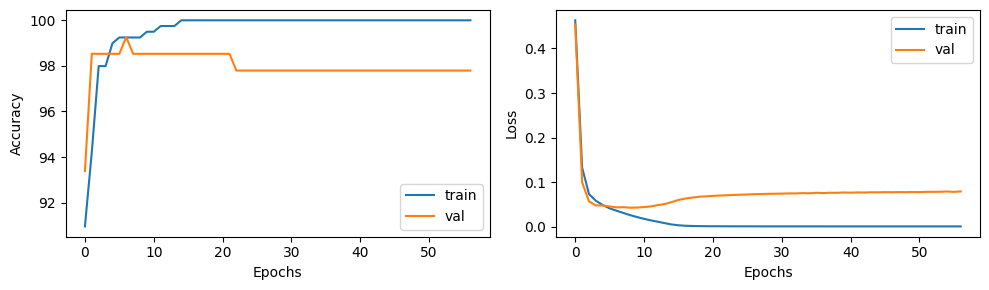

In [47]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
axes[0].plot(training_history['accuracy'], label='train')
axes[0].plot(validation_history['accuracy'], label='val')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(training_history['loss'], label='train')
axes[1].plot(validation_history['loss'], label='val')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
fig.tight_layout()

plt.show()

### Dropout

In [48]:
class DropoutModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout_prob=0.1):
        super(DropoutModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout_prob)
        self.relu = nn.ReLU()
        self.fc4 = nn.Linear(hidden_dim, hidden_dim)
        self.fc5 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.dropout(x)
        x = self.relu(self.fc4(x))
        x = self.fc5(x)
        return x

In [49]:
# model + optimizer + criterion
model = DropoutModel(input_size, hidden_dim, n_classes, dropout_prob=0.1)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# ignite trainer + evaluators
trainer = create_supervised_trainer(model, optimizer, criterion, device)
val_metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)}
train_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)
val_evaluator = create_supervised_evaluator(model, metrics=val_metrics, device=device)

training_history = {'accuracy':[],'loss':[]}
validation_history = {'accuracy':[],'loss':[]}

# loggers + history appends
@trainer.on(Events.ITERATION_COMPLETED(every=log_interval))
def log_training_loss(engine):
    print(f"Epoch[{engine.state.epoch}], Iter[{engine.state.iteration}] Loss: {engine.state.output:.2f}")

# after a training epoch, computes training and validation metrics (train_eval on train_loader and val_eval on val_loader)
@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(trainer):
    train_evaluator.run(train_loader)
    metrics = train_evaluator.state.metrics
    training_history['accuracy'].append(metrics['accuracy']*100)
    training_history['loss'].append(metrics['loss'])
    print(f"Training Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

@trainer.on(Events.EPOCH_COMPLETED)
def log_validation_results(trainer):
    val_evaluator.run(val_loader)
    metrics = val_evaluator.state.metrics
    validation_history['accuracy'].append(metrics['accuracy']*100)
    validation_history['loss'].append(metrics['loss'])
    print(f"Validation Results - Epoch[{trainer.state.epoch}] Avg accuracy: {metrics['accuracy']:.2f} Avg loss: {metrics['loss']:.2f}")

In [50]:
# Define early stopping and model checkpoint
handler = EarlyStopping(patience=50, score_function=score_function, trainer=trainer)
checkpoint = ModelCheckpoint('models', filename_prefix='best_DROP', n_saved=1, global_step_transform=global_step_from_engine(trainer), require_empty=False)

# Attach early stopping and model checkpoint to the trainer
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, handler)
val_evaluator.add_event_handler(Events.EPOCH_COMPLETED, checkpoint, {'model': model})

In [51]:
trainer.run(train_loader, max_epochs=300)

Training Results - Epoch[1] Avg accuracy: 0.94 Avg loss: 0.46
Validation Results - Epoch[1] Avg accuracy: 0.97 Avg loss: 0.45
Training Results - Epoch[2] Avg accuracy: 0.96 Avg loss: 0.11
Validation Results - Epoch[2] Avg accuracy: 0.97 Avg loss: 0.08
Training Results - Epoch[3] Avg accuracy: 0.98 Avg loss: 0.07
Validation Results - Epoch[3] Avg accuracy: 0.99 Avg loss: 0.05
Training Results - Epoch[4] Avg accuracy: 0.99 Avg loss: 0.05
Validation Results - Epoch[4] Avg accuracy: 0.99 Avg loss: 0.04
Training Results - Epoch[5] Avg accuracy: 0.99 Avg loss: 0.04
Validation Results - Epoch[5] Avg accuracy: 0.99 Avg loss: 0.04
Training Results - Epoch[6] Avg accuracy: 0.99 Avg loss: 0.04
Validation Results - Epoch[6] Avg accuracy: 0.99 Avg loss: 0.05
Training Results - Epoch[7] Avg accuracy: 0.99 Avg loss: 0.03
Validation Results - Epoch[7] Avg accuracy: 0.99 Avg loss: 0.04
Epoch[8], Iter[100] Loss: 0.01
Training Results - Epoch[8] Avg accuracy: 0.99 Avg loss: 0.03
Validation Results - Epoc

2024-05-07 10:55:09,494 ignite.handlers.early_stopping.EarlyStopping INFO: EarlyStopping: Stop training


Training Results - Epoch[44] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[44] Avg accuracy: 0.96 Avg loss: 0.17
Training Results - Epoch[45] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[45] Avg accuracy: 0.96 Avg loss: 0.17
Training Results - Epoch[46] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[46] Avg accuracy: 0.96 Avg loss: 0.17
Epoch[47], Iter[600] Loss: 0.00
Training Results - Epoch[47] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[47] Avg accuracy: 0.96 Avg loss: 0.17
Training Results - Epoch[48] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[48] Avg accuracy: 0.96 Avg loss: 0.18
Training Results - Epoch[49] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[49] Avg accuracy: 0.96 Avg loss: 0.18
Training Results - Epoch[50] Avg accuracy: 1.00 Avg loss: 0.00
Validation Results - Epoch[50] Avg accuracy: 0.96 Avg loss: 0.18
Training Results - Epoch[51] Avg accuracy: 1.00 Avg loss: 0.00
Validatio

State:
	iteration: 702
	epoch: 54
	epoch_length: 13
	max_epochs: 300
	output: 5.44954787073948e-07
	batch: <class 'list'>
	metrics: <class 'dict'>
	dataloader: <class 'torch.utils.data.dataloader.DataLoader'>
	seed: <class 'NoneType'>
	times: <class 'dict'>

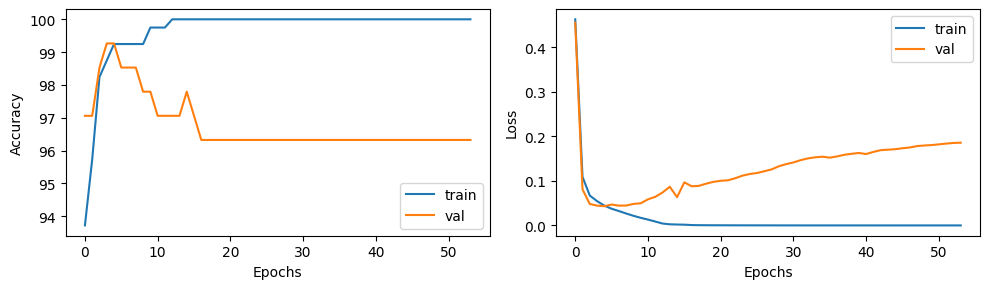

In [52]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
axes[0].plot(training_history['accuracy'], label='train')
axes[0].plot(validation_history['accuracy'], label='val')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(training_history['loss'], label='train')
axes[1].plot(validation_history['loss'], label='val')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
fig.tight_layout()

plt.show()

#### Model Comparison

In [53]:
# saved models
!ls models

best_DROP_model_54.pt  best_L2_model_57.pt    best_NOREG_model_53.pt


In [54]:
criterion = nn.CrossEntropyLoss() # same criterion used while training
metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)} # same metrics used while training

In [55]:
def evaluate_model(evaluator, test_loader, criterion):
    state = evaluator.run(test_loader)
    metrics = evaluator.state.metrics
    test_loss = metrics['loss']
    test_acc = metrics['accuracy']
    return test_loss, test_acc

In [56]:
# reinitialize models indentical to training to then load the state saved by pytorch ignite
best_NOREG_model = CustomModel(input_size, hidden_size1, hidden_size2, output_size)
best_NOREG_model.load_state_dict(torch.load('models/best_NOREG_model_53.pt'))

best_L2_model = L2Model(input_size, hidden_dim, n_classes)
best_L2_model.load_state_dict(torch.load('models/best_L2_model_57.pt'))

best_DROP_model = DropoutModel(input_size, hidden_dim, n_classes, dropout_prob=0.1)
best_DROP_model.load_state_dict(torch.load('models/best_DROP_model_54.pt'))

NOREG_evaluator = create_supervised_evaluator(best_NOREG_model, metrics=metrics, device=device) 
L2_evaluator = create_supervised_evaluator(best_L2_model, metrics=metrics, device=device) 
DROP_evaluator = create_supervised_evaluator(best_DROP_model, metrics=metrics, device=device) 

loss_ES, acc_ES = evaluate_model(NOREG_evaluator, test_loader, criterion)
loss_L2, acc_L2 = evaluate_model(L2_evaluator, test_loader, criterion)
loss_DROP, acc_DROP = evaluate_model(DROP_evaluator, test_loader, criterion)

print("Model without regularization - Loss: {:.4f}, Accuracy: {:.4f}".format(loss_ES, acc_ES))
print("Model with L2 regularization - Loss: {:.4f}, Accuracy: {:.4f}".format(loss_L2, acc_L2))
print("Model with Dropout - Loss: {:.4f}, Accuracy: {:.4f}".format(loss_DROP, acc_DROP))

Model without regularization - Loss: 0.3396, Accuracy: 0.9708
Model with L2 regularization - Loss: 0.0638, Accuracy: 0.9825
Model with Dropout - Loss: 0.1487, Accuracy: 0.9708


### Hyper-Parameter Tuning

In [57]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import RandomizedSearchCV
from ignite.engine import State

In [58]:
class PyTorchModel(nn.Module):
    def __init__(self, input_dim, hidden_layer_sizes, activation):
        super(PyTorchModel, self).__init__()
        layers = []
        prev_size = input_dim
        
        # create linear layers with specified hidden layer sizes
        for size in hidden_layer_sizes:
            layers.append(nn.Linear(prev_size, size))
            layers.append(activation)
            prev_size = size
        
        # final output layer
        layers.append(nn.Linear(prev_size, n_classes))
        
        # sequentially stack all layers
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        # pass input through all layers and apply softmax activation
        return torch.softmax(self.layers(x), dim=-1)

In [59]:
class PyTorchClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim, hidden_layer_sizes, activation, optimizer_class, lr, epochs, device, metrics, criterion, batch_size):
        self.input_dim = input_dim
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.optimizer_class = optimizer_class
        self.lr = lr
        self.epochs = epochs
        self.model = None
        self.optimizer = None
        self.device = device
        self.metrics = metrics
        self.criterion = criterion
        self.batch_size = batch_size


    def fit(self, X, y):
        print("=======================================================")
        print("Fitting on Parameters:", 
              f"Input Dimension: {self.input_dim},\n"
              f"Hidden Layer Sizes: {self.hidden_layer_sizes},\n"
              f"Activation: {self.activation},\n"
              f"Optimizer Class: {self.optimizer_class},\n"
              f"Learning Rate: {self.lr},\n"
              f"Epochs: {self.epochs},\n"
              f"Device: {self.device},\n"
              f"Metrics: {self.metrics},\n"
              f"Criterion: {self.criterion},\n"
              f"Batch Size: {self.batch_size},\n"
        )

        # number of classes needed by BaseEstimator in classes_ variable
        self.classes_ = np.unique(y) 

        # initialize model + optimizer
        self.model = PyTorchModel(self.input_dim, self.hidden_layer_sizes, self.activation)
        self.optimizer = self.optimizer_class(self.model.parameters(), lr=self.lr)

        # create train loader with input tensor (from numpy)
        tensor_dataset = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
        self.train_loader = DataLoader(tensor_dataset, batch_size=self.batch_size, shuffle=False)

        # initialize trainer and evaluator Pytorch Ignite
        self.trainer = create_supervised_trainer(self.model, self.optimizer, self.criterion, self.device)
        self.trainer.add_event_handler(Events.EPOCH_COMPLETED, self.log_training_results) # add logger handler to ignite trainer
        
        @self.trainer.on(Events.ITERATION_COMPLETED(every=10))
        def log_training_loss(engine):
            print(f"Epoch[{engine.state.epoch}], Iter[{engine.state.iteration}] Loss: {engine.state.output:.2f}")
        
        # reset trainer state and run train
        self.trainer.state = State() # needed by RandomizedSearchCV multiple fit
        self.trainer.run(self.train_loader, max_epochs=self.epochs)

    def predict(self, X):
        # create a data loader with the input tensor
        data_loader = DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32)), batch_size=self.batch_size, shuffle=False)
        
        # set the model to evaluation mode
        self.model.eval()
        
        predictions = []
        with torch.no_grad(): # temporarily disable gradient calculation (no gradient needed during evaluation)
            for inputs in data_loader:
                # forward pass through the model
                outputs = self.model(inputs[0])
                # compute predictions
                _, predicted = torch.max(outputs, 1)
                predictions.extend(predicted.tolist())
        
        return np.array(predictions)

    def log_training_results(self, trainer): 
        # custom loop here rather than ignite evaluate (it triggers errors due to the function scope)
        self.model.eval() # set the model to evaluation mode
        total_loss = 0.0
        correct = 0
        total = 0
    
        with torch.no_grad(): # temporarily disable gradient calculation (no gradient needed during evaluation)
            for inputs, targets in self.train_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)
                total_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                total += targets.size(0)
                correct += (predicted == targets).sum().item()
    
        accuracy = 100 * correct / total
        avg_loss = total_loss / len(self.train_loader)
    
        print(f"Training Results - Epoch[{trainer.state.epoch}] Avg accuracy: {accuracy:.2f} Avg loss: {avg_loss:.2f}")

In [60]:
param_grid = {
    'hidden_layer_sizes': [(128, 64, 32), (64, 32, 16), (256, 128, 64)],
    'activation': [nn.ReLU(), nn.Tanh()],
    'lr': [0.001, 0.01, 0.1, 1],
    'optimizer_class': [optim.Adam, optim.SGD],
    'epochs': [10, 50, 100, 200],
    'batch_size': [32, 64, 128]
}

In [61]:
clf = PyTorchClassifier(
    input_dim = input_size,
    hidden_layer_sizes = (128, 64),
    activation = nn.ReLU(),
    optimizer_class = optim.Adam,
    lr = 0.001,
    epochs = 50,
    device = device,
    metrics = {"accuracy": Accuracy(), "loss": Loss(criterion)},
    criterion = nn.CrossEntropyLoss(),
    batch_size = 32
)

In [62]:
# perform randomized grid search
rs = RandomizedSearchCV(clf, param_grid, scoring='accuracy', verbose=True, n_iter=15, cv=3, error_score='raise')
rs.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Fitting on Parameters: Input Dimension: 30,
Hidden Layer Sizes: (256, 128, 64),
Activation: Tanh(),
Optimizer Class: <class 'torch.optim.sgd.SGD'>,
Learning Rate: 0.1,
Epochs: 10,
Device: cpu,
Metrics: {'accuracy': <ignite.metrics.metrics_lambda.MetricsLambda object at 0x2a920f290>, 'loss': <ignite.metrics.metrics_lambda.MetricsLambda object at 0x2a1f38890>},
Criterion: CrossEntropyLoss(),
Batch Size: 32,

Training Results - Epoch[1] Avg accuracy: 93.58 Avg loss: 0.49
Epoch[2], Iter[10] Loss: 0.49
Training Results - Epoch[2] Avg accuracy: 94.72 Avg loss: 0.41
Epoch[3], Iter[20] Loss: 0.39
Training Results - Epoch[3] Avg accuracy: 96.60 Avg loss: 0.39
Epoch[4], Iter[30] Loss: 0.38
Training Results - Epoch[4] Avg accuracy: 96.60 Avg loss: 0.37
Epoch[5], Iter[40] Loss: 0.33
Training Results - Epoch[5] Avg accuracy: 97.74 Avg loss: 0.36
Epoch[6], Iter[50] Loss: 0.36
Training Results - Epoch[6] Avg accuracy: 97.74 Avg loss: 0.35
E

RandomizedSearchCV(cv=3, error_score='raise',
                   estimator=PyTorchClassifier(activation=ReLU(), batch_size=32,
                                               criterion=CrossEntropyLoss(),
                                               device=device(type='cpu'),
                                               epochs=50,
                                               hidden_layer_sizes=(128, 64),
                                               input_dim=30, lr=0.001,
                                               metrics={'accuracy': <ignite.metrics.accuracy.Accuracy object at 0x2a93634a0>,
                                                        'loss': <ignite.metrics.loss.Loss object at 0x2a9361490>},
                                               optimizer_class=<class 'torch.optim.adam.Adam'>),
                   n_iter=15,
                   param_distributions={'activation': [ReLU(), Tanh()],
                                        'batch_size': [32, 64, 128],
                                        'epochs': [10, 50, 100, 200],
                                        'hidden_layer_sizes': [(128, 64, 32),
                                                               (64, 32, 16),
                                                               (256, 128, 64)],
                                        'lr': [0.001, 0.01, 0.1, 1],
                                        'optimizer_class': [<class 'torch.optim.adam.Adam'>,
                                                            <class 'torch.optim.sgd.SGD'>]},
                   scoring='accuracy', verbose=True)

In [63]:
print(rs.best_score_, rs.best_params_)

0.977405635300372 {'optimizer_class': <class 'torch.optim.sgd.SGD'>, 'lr': 0.1, 'hidden_layer_sizes': (128, 64, 32), 'epochs': 200, 'batch_size': 32, 'activation': Tanh()}


In [65]:
y_pred = rs.predict(X_test).astype(int)

print('Accuracy %s' % accuracy_score(y_test, y_pred))
print('F1-score %s' % f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))

Accuracy 0.9766081871345029
F1-score [0.96825397 0.98148148]
              precision    recall  f1-score   support

           0       0.98      0.95      0.97        64
           1       0.97      0.99      0.98       107

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171

